# DINGO MCMC with fixed center and inclination

This is the same simple three-file R+C model, with **$x_0$, $y_0$, and $i$ held fixed in both the local fit and MCMC**. No earlier fits or candidate search are required. Use the **grism** kernel; restart it before the first run to load the updated functions.

The sampled parameters are $V_\infty$ (km/s), turnover radius (pixels), cutout orientation, and the two R registration offsets (pixels). Intrinsic dispersion is zero. **Velocity intervals are conditional on the chosen fixed geometry; they do not include inclination or center uncertainty.** Fixing geometry is a diagnostic experiment, not a guarantee of a correct velocity.

In [2]:
from pathlib import Path
import os
import sys
import logging
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Set the fixed geometry and starting fit

Edit `fixed_x0`, `fixed_y0`, and `fixed_inclination` below. Center coordinates are **absolute, zero-based pixels**: (40, 40) is the geometric center of an 81×81 cutout. This is not automatically a measured galaxy center. Inclination is in degrees; 75° is an editable assumption for this experiment.

The remaining starting values are rounded from the earlier 6170 moderate-velocity fit. They are explicit numbers, not a dependency on saved files. Once center and inclination are fixed to your choices, this is a different conditional fit.

Each source has its own folder under `OUTPUT_ROOT`. Change `run_name` when comparing experiments; `overwrite=True` replaces only that named experiment. Setting any `fixed_*` argument to `None` frees that parameter. If inclination is freed, set `inclination_mean` and `inclination_sigma` explicitly for its Gaussian prior.

ID6170: explicit V_inf=450 km/s; fixed i=75 deg.
Saving to /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_v450
Fixed: x0=40 px, y0=40 px, i=75 deg. Excluded from optimization and MCMC; intervals are conditional on these values.
Sampled parameters: ['velocity.V_rot', 'velocity.R_v', 'velocity.theta_v', 'image.R.dx', 'image.R.dy']


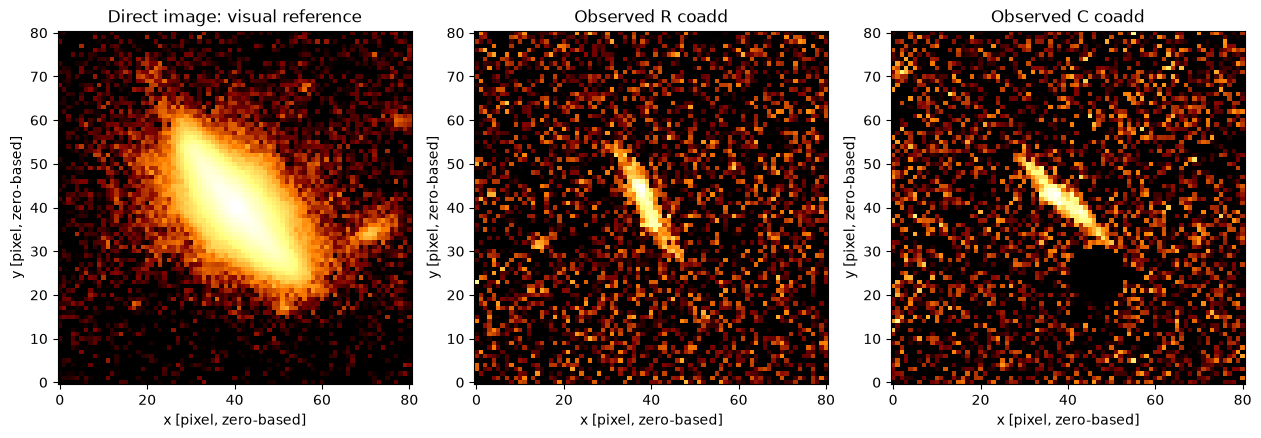

In [3]:
run = sm.prepare(
    6170,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name="fixed_x40_y40_i75_v450",
    overwrite=True,
    device="cuda",                 # or "cpu"

    fixed_x0=40.0,                 # FIXED, pixels
    fixed_y0=40.0,                 # FIXED, pixels
    fixed_inclination=75.0,        # FIXED, degrees; no Gaussian i prior is used

    start_velocity=450.0,          # sampled V_inf, km/s
    start_turnover=10.09,          # sampled R_t, pixels
    start_pa=286.64,               # sampled cutout orientation, degrees
    start_offset=(1.0625, 0.2852),  # sampled R registration dx,dy, pixels
    max_velocity=1000.0,
)
print("Sampled parameters:", run.fitter.mcmc_param_names)
fig = sm.show_inputs(run)
display(fig)
plt.close(fig)

## 2. Fit the remaining parameters and inspect residuals

This optional local optimization cannot move the fixed center or inclination. It uses the same posterior as MCMC. The cyan cross marks the fixed kinematic center. Skip `sm.fit_local(...)` to sample directly from the explicit starting values.

Local fit evaluations:   0%|          | 0/3000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (155 evaluations).


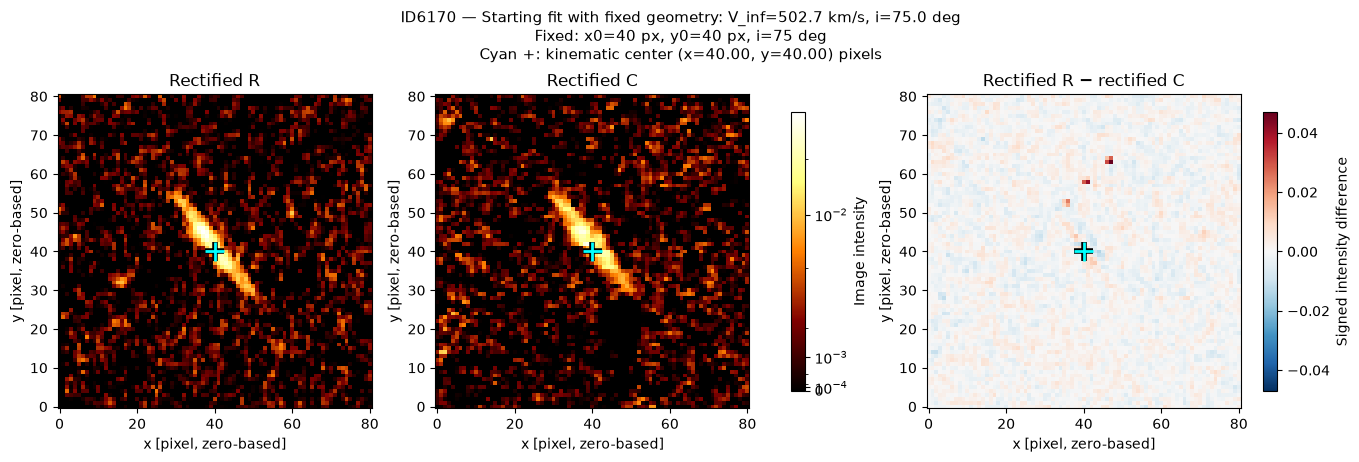

In [4]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Starting fit with fixed geometry")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

Warmup is discarded; draws are retained per walker. For a quick execution check use `warmup=100, draws=200, walkers=32`. Progress and checkpoints work as in the simple notebook. Completion alone does not establish convergence. This uses emcee with the PyTorch likelihood batched on the GPU.

In [5]:
RESULT_DIR = sm.sample(
    run,
    warmup=1000,
    draws=4000,
    walkers=64,
    seed=42,
    progress="notebook",           # use True for a text progress bar
)
print(RESULT_DIR)

Warmup:   0%|          | 0/1000 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/4000 [00:00<?, ?it/s]

finished: 4000 retained steps per walker.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_v450
/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_v450


## 4. View saved results

The corner plot contains **only sampled parameters**; fixed values are printed in its title and saved in `run_info.txt` and the NPZ files. The table gives pooled median and 16–84% intervals. Residuals use one actual maximum-posterior sample.

To reopen results after restarting, run the imports and this cell with `RESULT_DIR` set below. Do not rerun preparation with `overwrite=True` merely to view results.

Status: finished; retained steps/walker: 4000; latest segment mean acceptance: 0.224
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Fixed: x0=40 px, y0=40 px, i=75 deg. These quantities were not sampled; their uncertainty is not included.
Autocorrelation time per parameter: {'velocity.V_rot': 25.692765058602614, 'velocity.R_v': 25.161612942822348, 'velocity.theta_v': 24.841448267886804, 'image.R.dx': 20.764908319617977, 'image.R.dy': 19.907779250273038}


,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,
V_inf,853.400867,15.469870,15.488649,km/s
R_t,26.478734,0.738991,0.762131,pixel
cutout_PA,295.843771,0.453266,0.423449,deg
R_x_offset,1.433603,0.049296,0.043746,pixel
R_y_offset,0.281689,0.015953,0.015945,pixel


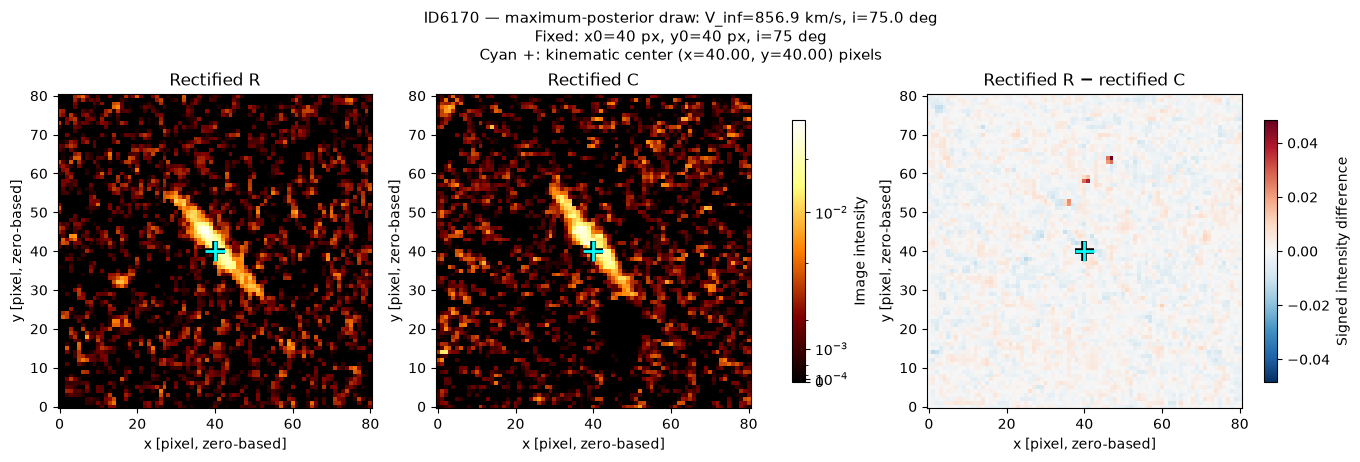

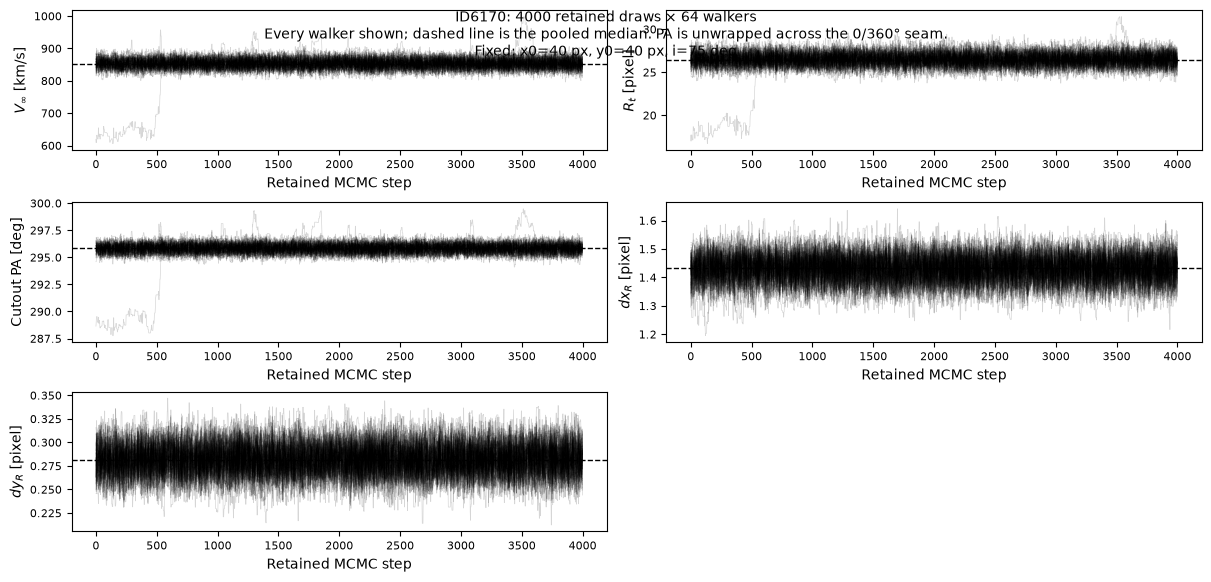

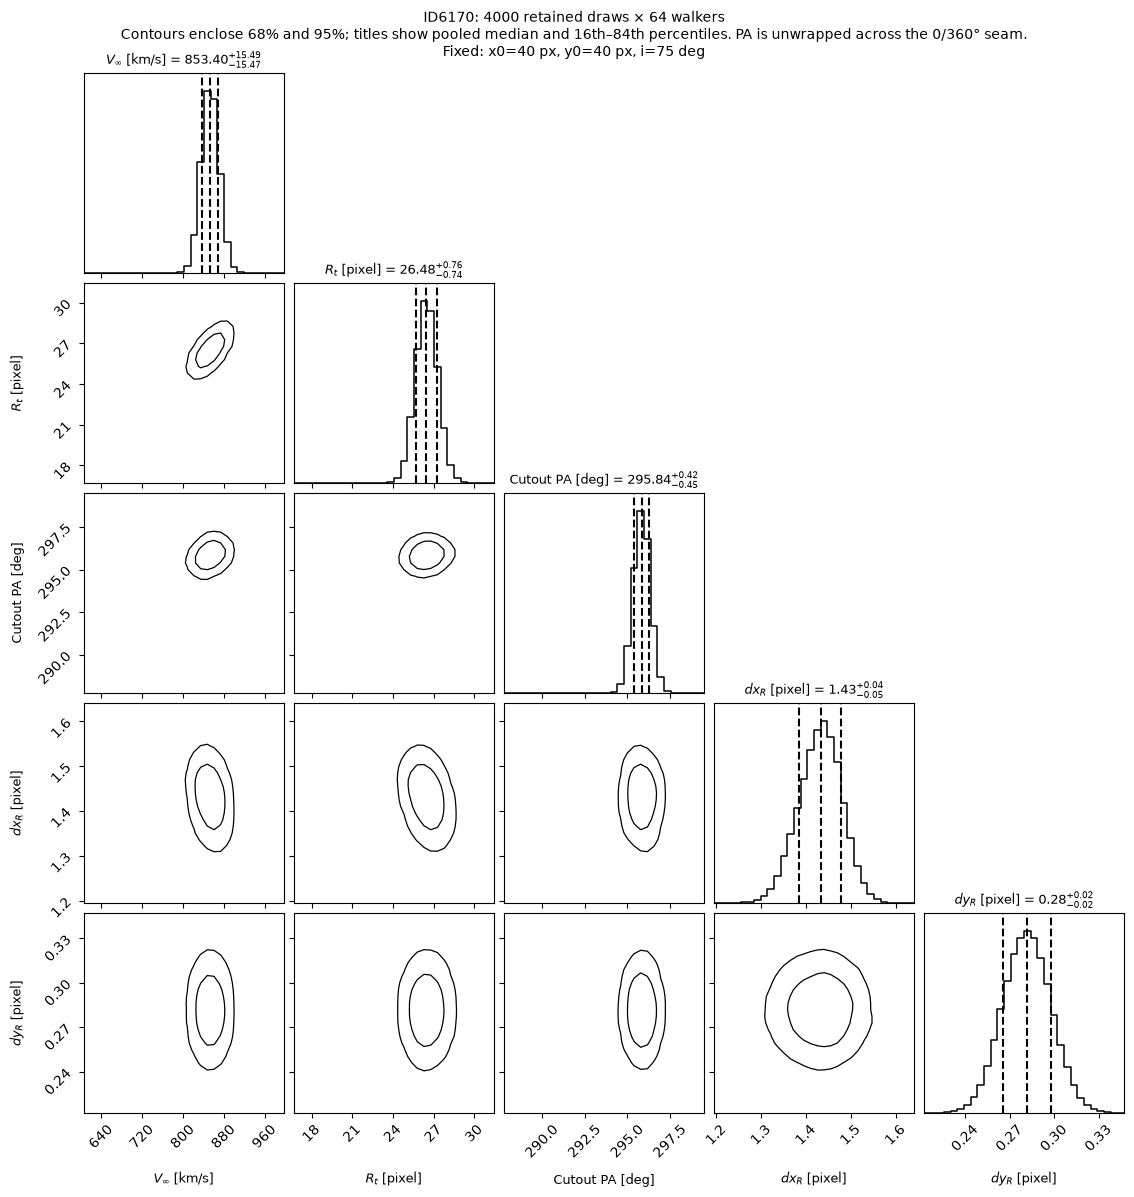

In [6]:
# To open saved results without fitting:
# RESULT_DIR = OUTPUT_ROOT / "6170" / "fixed_x40_y40_i75_v450"
views = sm.show_results(RESULT_DIR)
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

The likelihood is the original full-image squared corrected R−C residual divided by a fixed noise variance estimated from the input stacks. This does not fully propagate coadd/interpolation covariance. The remaining priors are uniform $V_\infty$ from 0 to `max_velocity`, log-uniform turnover radius from 0.5 pixels to the cutout half-width, full-turn uniform orientation, and Gaussian R registration offsets about zero with width 2 pixels (truncated at ±10). Fixed center/inclination priors are removed.

A velocity piling up at its bound is still not a measured plateau speed. Inspect residuals, traces and independent starting points before quoting uncertainties.

Results are saved in `OUTPUT_ROOT/source_ID/run_name/`. To resume after a kernel restart: `run = sm.open_run(saved_directory)`, then `sm.sample(run, warmup=1000, draws=4000, walkers=64, resume=True, progress="notebook")`, preserving the original warmup and walker count. To change fixed geometry, prepare a different named experiment.